# ====================================================
# PHASE 1 — ENVIRONMENT SETUP
# ====================================================
Installation of required dependencies and directory setup.

In [1]:
!pip install -q transformers peft accelerate scikit-learn einops evaluate biopython

import os

PROJECT_DIR = "/content/DNABERT2"
DATASET_DIR = "/content/datasets"

# Create project structure
for folder in ["datasets", "tokenizer", "checkpoints", "logs", "outputs"]:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)
os.makedirs(DATASET_DIR, exist_ok=True)

print("Environment Setup Complete.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 71.7 MB/s eta 0:00:00
Environment Setup Complete.


# ====================================================
# PHASE 2 — IMPORTS
# ====================================================
Consolidated library imports.

In [2]:
# Standard Library
import os
import random
import math
import numpy as np
import pandas as pd
from tqdm import tqdm

# Third Party Libraries
from Bio import SeqIO
from sklearn.model_selection import train_test_split
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import ByteLevel

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

# HuggingFace
from transformers import get_cosine_schedule_with_warmup

# ====================================================
# PHASE 3 — CONFIGURATION
# ====================================================
Global hyperparameters and reproducibility settings.

In [3]:
class Config:
    # Data
    WINDOW_SIZE = 512
    STRIDE = 512
    MIN_LENGTH = 100
    SEED = 42

    # Tokenizer
    VOCAB_SIZE = 4096

    # Model
    HIDDEN_SIZE = 256
    NUM_HEADS = 8
    NUM_LAYERS = 6
    FFN_HIDDEN_SIZE = 1024
    DROPOUT = 0.1

    # Training
    BATCH_SIZE = 8
    EPOCHS = 5
    LEARNING_RATE = 5e-4
    MLM_PROBABILITY = 0.15

# Set device and seeds
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
random.seed(Config.SEED)
np.random.seed(Config.SEED)
torch.manual_seed(Config.SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(Config.SEED)

# ====================================================
# PHASE 4 — DATASET PREPARATION
# ====================================================
Loading the E. coli genome, cleaning sequences, and generating windows.

In [4]:
# Download and Unzip
%cd /content/datasets
!wget -q -O ecoli.fna.gz https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/000/005/845/GCF_000005845.2_ASM584v2/GCF_000005845.2_ASM584v2_genomic.fna.gz
!gunzip -f ecoli.fna.gz

# Parse and Clean
records = list(SeqIO.parse("/content/datasets/ecoli.fna", "fasta"))
sequence = str(records[0].seq).upper()
cleaned_sequence = "".join([base for base in sequence if base in "ACGT"])

# Windowing
windows = [cleaned_sequence[i:i + Config.WINDOW_SIZE]
           for i in range(0, len(cleaned_sequence) - Config.WINDOW_SIZE + 1, Config.STRIDE)]

# Train/Val Split
train_sequences, valid_sequences = train_test_split(
    windows, test_size=0.2, random_state=Config.SEED, shuffle=True
)

print(f"Windows: {len(windows)} | Train: {len(train_sequences)} | Val: {len(valid_sequences)}")

/content/datasets
Windows: 9065 | Train: 7252 | Val: 1813


### DATA INSPECTION
We visualize the results of the genome parsing and windowing process to ensure the data is correctly structured for training.

--- Dataset Summary ---
Total Windows: 9065
Min Length:    512
Max Length:    512
Mean Length:   512.00


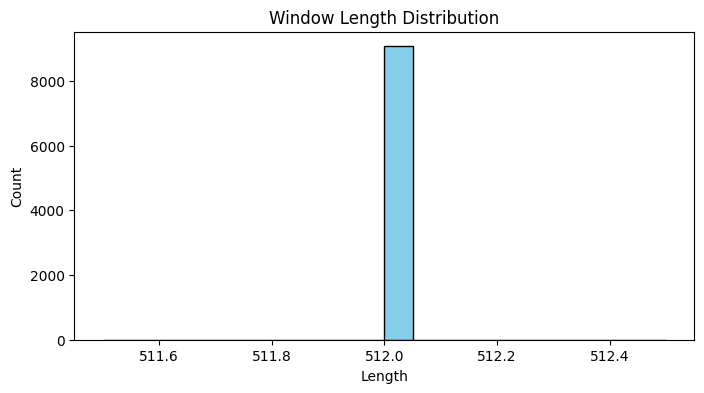


--- Sample Window (First 100bp) ---
AGCTTTTCATTCTGACTGCAACGGGCAATATGTCTCTGTGTGGATTAAAAAAAGAGTGTCTGATAGCAGCTTCTGAACTGGTTACCTGCCGTGAGTAAAT


In [5]:
import matplotlib.pyplot as plt

# Statistics
window_lengths = [len(w) for w in windows]
print(f"--- Dataset Summary ---")
print(f"Total Windows: {len(windows)}")
print(f"Min Length:    {min(window_lengths)}")
print(f"Max Length:    {max(window_lengths)}")
print(f"Mean Length:   {np.mean(window_lengths):.2f}")

# Distribution
plt.figure(figsize=(8, 4))
plt.hist(window_lengths, bins=20, color='skyblue', edgecolor='black')
plt.title("Window Length Distribution")
plt.xlabel("Length")
plt.ylabel("Count")
plt.show()

# Sample Inspection
print(f"\n--- Sample Window (First 100bp) ---")
print(windows[0][:100])

# ====================================================
# PHASE 5 — TOKENIZATION
# ====================================================
Training the BPE tokenizer and defining special token IDs.

In [6]:
train_txt = os.path.join(PROJECT_DIR, "datasets/train.txt")
with open(train_txt, "w") as f: f.write("\n".join(train_sequences))

# Train BPE Tokenizer
tokenizer = Tokenizer(BPE())
tokenizer.pre_tokenizer = ByteLevel(add_prefix_space=False)
special_tokens = ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"]
trainer = BpeTrainer(vocab_size=Config.VOCAB_SIZE, min_frequency=2, special_tokens=special_tokens)
tokenizer.train(files=[train_txt], trainer=trainer)

# Save and reload
tokenizer.save("/content/dnabert2_tokenizer.json")
tokenizer = Tokenizer.from_file("/content/dnabert2_tokenizer.json")

# Constants for ID mapping
PAD_ID = tokenizer.token_to_id("[PAD]")
MASK_ID = tokenizer.token_to_id("[MASK]")
CLS_ID = tokenizer.token_to_id("[CLS]")
SEP_ID = tokenizer.token_to_id("[SEP]")

### TOKENIZATION INSPECTION
Verifying that the BPE tokenizer correctly handles the DNA sequences and that special tokens are mapped properly.

In [7]:
sample_seq = train_sequences[0]
encoded = tokenizer.encode(sample_seq)

print(f"--- Tokenization Test ---")
print(f"Original Length: {len(sample_seq)}")
print(f"Token IDs Count: {len(encoded.ids)}")
print(f"First 10 Tokens: {encoded.tokens[:10]}")
print(f"First 10 IDs:    {encoded.ids[:10]}")
print(f"Decoded:         {tokenizer.decode(encoded.ids[:10])}")

print(f"\n--- Special Token Mapping ---")
for name, idx in [("[PAD]", PAD_ID), ("[MASK]", MASK_ID), ("[CLS]", CLS_ID), ("[SEP]", SEP_ID)]:
    print(f"{name:7} : ID {idx}")

--- Tokenization Test ---
Original Length: 512
Token IDs Count: 103
First 10 Tokens: ['C', 'ACGGTT', 'TAAG', 'TGCCAA', 'TGCCG', 'ATGCCTG', 'GGTT', 'ACGCATT', 'GCGAA', 'AACG']
First 10 IDs:    [6, 1283, 124, 637, 119, 1486, 107, 2863, 118, 56]
Decoded:         C ACGGTT TAAG TGCCAA TGCCG ATGCCTG GGTT ACGCATT GCGAA AACG

--- Special Token Mapping ---
[PAD]   : ID 0
[MASK]  : ID 4
[CLS]   : ID 2
[SEP]   : ID 3


# ====================================================
# PHASE 6 — MODEL ARCHITECTURE
# ====================================================
Custom implementation of DNABERT-2 with ALiBi attention.

In [8]:
class DNAEmbedding(nn.Module):
    def __init__(self, vocab_size, hidden_size, dropout):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, hidden_size)
        self.layer_norm = nn.LayerNorm(hidden_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, input_ids):
        return self.dropout(self.layer_norm(self.token_embedding(input_ids)))

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, hidden_size, num_heads, dropout):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = hidden_size // num_heads
        self.query, self.key, self.value = [nn.Linear(hidden_size, hidden_size) for _ in range(3)]
        self.output = nn.Linear(hidden_size, hidden_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask):
        B, L, D = x.size()
        Q = self.query(x).view(B, L, self.num_heads, self.head_dim).permute(0, 2, 1, 3)
        K = self.key(x).view(B, L, self.num_heads, self.head_dim).permute(0, 2, 1, 3)
        V = self.value(x).view(B, L, self.num_heads, self.head_dim).permute(0, 2, 1, 3)

        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.head_dim)

        # ALiBi
        slopes = torch.tensor([2**(-8*(i+1)/self.num_heads) for i in range(self.num_heads)], device=x.device)
        rel_pos = (torch.arange(L, device=x.device)[None, :] - torch.arange(L, device=x.device)[:, None]).abs()
        scores -= (slopes[:, None, None] * rel_pos).unsqueeze(0)

        if mask is not None:
            scores = scores.masked_fill(mask.unsqueeze(1).unsqueeze(2) == 0, float("-inf"))

        attn = torch.softmax(scores, dim=-1)
        out = torch.matmul(self.dropout(attn), V).permute(0, 2, 1, 3).contiguous().view(B, L, D)
        return self.output(out)

class EncoderBlock(nn.Module):
    def __init__(self, h, heads, inter, drop):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(h), nn.LayerNorm(h)
        self.attn = MultiHeadSelfAttention(h, heads, drop)
        self.ffn = nn.Sequential(nn.Linear(h, inter), nn.GELU(), nn.Dropout(drop), nn.Linear(inter, h))

    def forward(self, x, mask):
        x = x + self.attn(self.norm1(x), mask)
        x = x + self.ffn(self.norm2(x))
        return x

class DNABERT2ForMLM(nn.Module):
    def __init__(self, v, h, heads, inter, layers, drop):
        super().__init__()
        self.embedding = DNAEmbedding(v, h, drop)
        self.layers = nn.ModuleList([EncoderBlock(h, heads, inter, drop) for _ in range(layers)])
        self.mlm_head = nn.Sequential(nn.Linear(h, h), nn.GELU(), nn.LayerNorm(h), nn.Linear(h, v))

    def forward(self, ids, mask):
        x = self.embedding(ids)
        for layer in self.layers: x = layer(x, mask)
        return self.mlm_head(x)

### MODEL INSPECTION
Analyzing the model structure and parameter count to ensure it fits within memory constraints.

In [9]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

test_model = DNABERT2ForMLM(Config.VOCAB_SIZE, Config.HIDDEN_SIZE, Config.NUM_HEADS, Config.FFN_HIDDEN_SIZE, Config.NUM_LAYERS, Config.DROPOUT)

print(f"--- Model Architecture Summary ---")
print(f"Total Trainable Parameters: {count_parameters(test_model):,}")
print(f"Backbone: DNABERT-2 (ALiBi Attention)")
print(f"Layers:   {Config.NUM_LAYERS} | Heads: {Config.NUM_HEADS} | Hidden: {Config.HIDDEN_SIZE}")

# Dummy forward pass
dummy_ids = torch.randint(0, Config.VOCAB_SIZE, (1, 128))
dummy_mask = torch.ones((1, 128))
with torch.no_grad():
    output = test_model(dummy_ids, dummy_mask)
print(f"Output Shape: {output.shape} (Batch, Seq, Vocab)")

--- Model Architecture Summary ---
Total Trainable Parameters: 6,906,624
Backbone: DNABERT-2 (ALiBi Attention)
Layers:   6 | Heads: 8 | Hidden: 256
Output Shape: torch.Size([1, 128, 4096]) (Batch, Seq, Vocab)


# ====================================================
# PHASE 7 — TRAINING UTILITIES
# ====================================================
MLM logic and data loading classes.

In [10]:
def create_mlm_labels(input_ids, vocab_size, mask_id, pad_id, cls_id, sep_id, prob=0.15):
    labels = input_ids.clone()
    inputs = input_ids.clone()
    prob_matrix = torch.full(labels.shape, prob, device=input_ids.device)
    special_mask = (inputs == pad_id) | (inputs == cls_id) | (inputs == sep_id)
    prob_matrix.masked_fill_(special_mask, 0.0)

    masked_indices = torch.bernoulli(prob_matrix).bool()
    labels[~masked_indices] = -100

    indices_replaced = torch.bernoulli(torch.full(labels.shape, 0.8, device=input_ids.device)).bool() & masked_indices
    inputs[indices_replaced] = mask_id

    indices_random = torch.bernoulli(torch.full(labels.shape, 0.5, device=input_ids.device)).bool() & masked_indices & ~indices_replaced
    inputs[indices_random] = torch.randint(vocab_size, labels.shape, dtype=torch.long, device=input_ids.device)[indices_random]

    return inputs, labels

class DNADataset(Dataset):
    def __init__(self, seqs, tok): self.seqs = seqs; self.tok = tok
    def __len__(self): return len(self.seqs)
    def __getitem__(self, i): return {"input_ids": self.tok.encode(self.seqs[i]).ids}

def collate_fn(batch):
    ids = [torch.tensor(x["input_ids"]) for x in batch]
    padded = torch.nn.utils.rnn.pad_sequence(ids, batch_first=True, padding_value=PAD_ID)
    return {"input_ids": padded, "attention_mask": (padded != PAD_ID).long()}

### DATALOADER & MLM INSPECTION
Visualizing the masking process to confirm that labels are only generated for masked tokens and that padding is handled.

In [11]:
test_loader = DataLoader(DNADataset(train_sequences[:10], tokenizer), batch_size=2, collate_fn=collate_fn)
batch = next(iter(test_loader))
ids, mask = batch["input_ids"], batch["attention_mask"]

m_ids, labels = create_mlm_labels(ids, Config.VOCAB_SIZE, MASK_ID, PAD_ID, CLS_ID, SEP_ID, Config.MLM_PROBABILITY)

print(f"--- Batch Inspection ---")
print(f"Input IDs Shape:  {ids.shape}")
print(f"Labels Shape:     {labels.shape}")
print(f"Device:           {device}")

print(f"\n--- Masking Verification (First Sequence) ---")
masked_tokens = (labels[0] != -100).sum().item()
print(f"Total Tokens:  {len(ids[0])}")
print(f"Masked Tokens: {masked_tokens} ({masked_tokens/len(ids[0]):.1%})")

# Show actual masked indices
masked_idx = (labels[0] != -100).nonzero(as_tuple=True)[0]
print(f"Indices targeted for loss: {masked_idx[:10].tolist()}...")

--- Batch Inspection ---
Input IDs Shape:  torch.Size([2, 103])
Labels Shape:     torch.Size([2, 103])
Device:           cuda

--- Masking Verification (First Sequence) ---
Total Tokens:  103
Masked Tokens: 15 (14.6%)
Indices targeted for loss: [4, 7, 18, 30, 40, 49, 50, 54, 55, 59]...


# ====================================================
# PHASE 8 — TRAINING EXECUTION
# ====================================================
Main training loop.

In [ ]:
train_loader = DataLoader(DNADataset(train_sequences, tokenizer), batch_size=Config.BATCH_SIZE, shuffle=True, collate_fn=collate_fn)

model = DNABERT2ForMLM(Config.VOCAB_SIZE, Config.HIDDEN_SIZE, Config.NUM_HEADS, Config.FFN_HIDDEN_SIZE, Config.NUM_LAYERS, Config.DROPOUT).to(device)
optimizer = AdamW(model.parameters(), lr=Config.LEARNING_RATE, weight_decay=0.01)
criterion = nn.CrossEntropyLoss(ignore_index=-100)
scheduler = get_cosine_schedule_with_warmup(optimizer, int(0.1*len(train_loader)*Config.EPOCHS), len(train_loader)*Config.EPOCHS)

model.train()
for epoch in range(Config.EPOCHS):
    total_loss = 0
    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}"):
        ids, mask = batch["input_ids"].to(device), batch["attention_mask"].to(device)
        masked_ids, labels = create_mlm_labels(ids, Config.VOCAB_SIZE, MASK_ID, PAD_ID, CLS_ID, SEP_ID, Config.MLM_PROBABILITY)

        optimizer.zero_grad()
        loss = criterion(model(masked_ids, mask).view(-1, Config.VOCAB_SIZE), labels.view(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        total_loss += loss.item()

    print(f"Avg Loss: {total_loss/len(train_loader):.4f}")

Epoch 1:  31%|███       | 279/907 [00:20<01:23,  7.48it/s]